# Praktikum 1

In [1]:
import torch
print("PyTorch Version:", torch.__version__)

cache_dir = "~/models"
width = 512
height = 512

PyTorch Version: 2.14.1+cu126


In [4]:
import sys

print(sys.executable)
!df -h

/home/jovyan/conda/projekt/bin/python
Filesystem      Size  Used Avail Use% Mounted on
overlay         1.9T  127G  1.7T   7% /
tmpfs            64M     0   64M   0% /dev
tmpfs            30G  4.0K   30G   1% /dev/shm
/dev/rbd1        49G   21G   29G  42% /home/jovyan
/dev/nvme0n1p4  1.9T  127G  1.7T   7% /etc/hosts
none            378G  4.2M  378G   1% /run/nvidia-persistenced/socket
none            256K  256K     0 100% /usr/local/bin/nvidia-smi
rootfs          377G  587M  377G   1% /usr/lib/firmware/nvidia/580.178.04/gsp_ga10x.bin
tmpfs           4.0K  4.0K     0 100% /run/nvidia-ctk-hook59c1ea47-1fc4-4baf-b01e-b09b0eb89657
tmpfs           4.0K     0  4.0K   0% /proc/acpi


### Pipelines

In [31]:
import gc

# Clear cache
#del pipeline
gc.collect()
torch.cuda.empty_cache()

In [21]:
from diffusers import StableDiffusionPipeline
from diffusers import DiffusionPipeline

# Stable Diffusion v1-5
# kleines Modell, 0.9 Milliarden Parameter
def sd15_pipeline():
    return StableDiffusionPipeline.from_pretrained(
        "sd-legacy/stable-diffusion-v1-5",
        use_safetensors=True,
        trust_remote_code=True,
        cache_dir=cache_dir,
    ).to("cuda")

# Stable Diffusion x1
# kleineres Modell, 3 Milliarden Parameter
def sdxl_pipeline():
    return DiffusionPipeline.from_pretrained(
        "stabilityai/stable-diffusion-xl-base-1.0", 
        torch_dtype=torch.float16, 
        use_safetensors=True, 
        variant="fp16", #half precision
    ).to("cuda")

# Midjourney Graffiti
# kleines Modell, 0.9 Milliarden Parameter
def midjourney_pipeline():
    return DiffusionPipeline.from_pretrained(
        "ShadoWxShinigamI/midjourney-graffiti",
        use_safetensors=True,
        trust_remote_code=True,
        cache_dir=cache_dir,
        dtype=torch.bfloat16 #half precision
    ).to("cuda")


pipeline = sd15_pipeline()


Loading pipeline components...: 100%|██████████| 7/7 [00:00<00:00,  8.87it/s]


### Variation der Steps

100%|██████████| 53/53 [00:08<00:00,  6.61it/s]


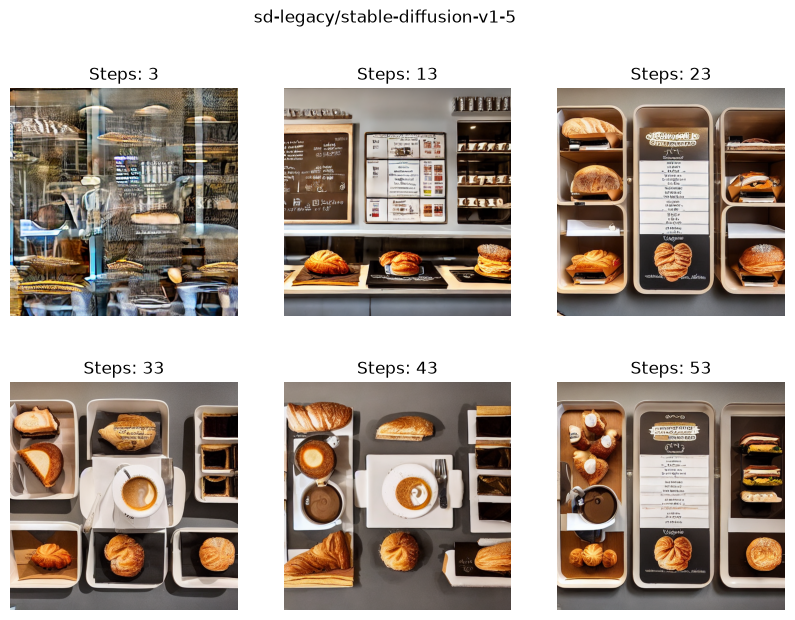

In [23]:
#prompt = "a magical sheep in a fantasy landscape, highly detailed, cinematic lighting"
prompt = "a quadratic menu for a little cafe in paris, with different types of coffee, pastries and sandwiches, in a modern and minimalist style"

images = []
for i in range(6):
    image = pipeline(prompt=prompt, 
                     num_inference_steps=i*10 + 3,
                    width=width,
                    height=height,
                   generator=torch.Generator(device="cuda").manual_seed(42)
                    
    ).images[0]
    images.append(image)


import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 3, figsize=(10, 7))

fig.suptitle(pipeline.name_or_path)
for i, ax in enumerate(axs.flatten()):
    ax.imshow(images[i])
    ax.axis('off')
    ax.title.set_text(f"Steps: {i*10 + 3}")



### Verschiedene Seeds

  0%|          | 0/50 [00:00<?, ?it/s]

100%|██████████| 50/50 [00:07<00:00,  6.63it/s]


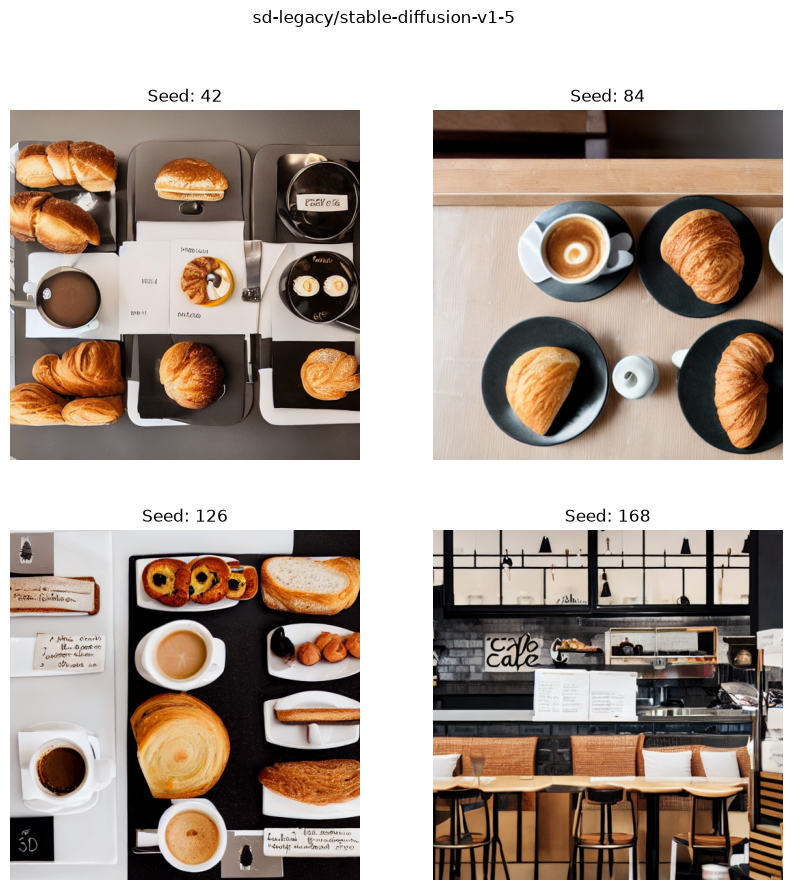

In [25]:
#prompt = "a magical sheep in a fantasy landscape, highly detailed, cinematic lighting"
prompt = "a quadratic menu for a little cafe in paris, with different types of coffee, pastries and sandwiches, in a modern and minimalist style"

images = []
for i in range(4):
    image = pipeline(prompt=prompt, 
                     num_inference_steps=50,
                    width=width,
                    height=height,
                   generator=torch.Generator(device="cuda").manual_seed((i+1) * 42)
                    
    ).images[0]
    images.append(image)


import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(10, 10))

fig.suptitle(pipeline.name_or_path)
for i, ax in enumerate(axs.flatten()):
    ax.imshow(images[i])
    ax.axis('off')
    ax.title.set_text(f"Seed: {(i+1) * 42}")

### Guidance Scale

100%|██████████| 50/50 [00:07<00:00,  6.63it/s]


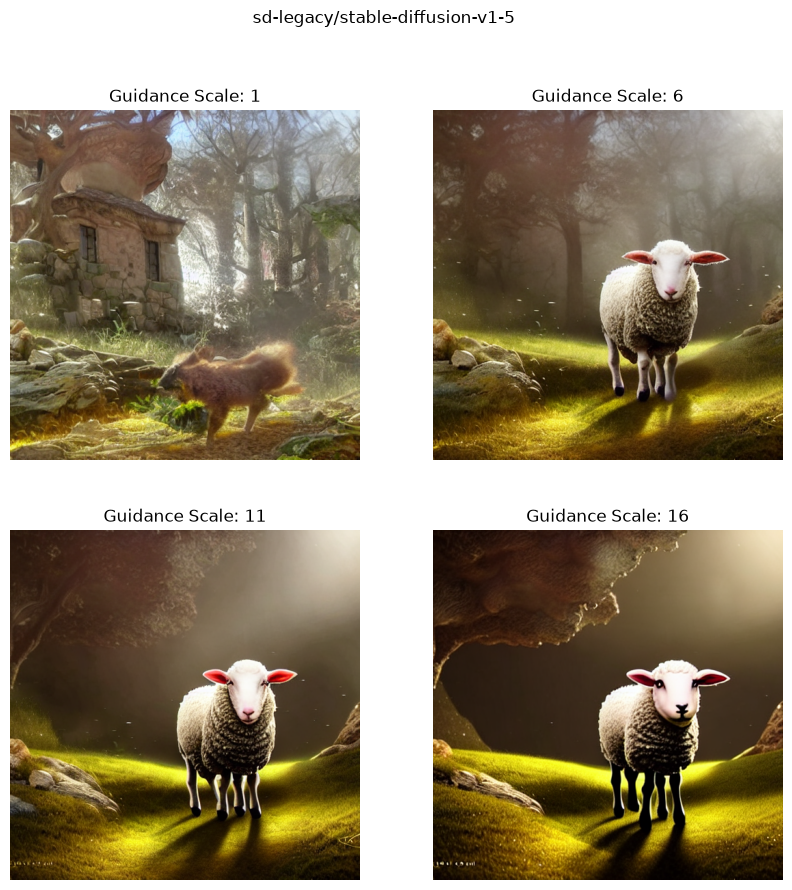

In [26]:
prompt = "a magical sheep in a fantasy landscape, highly detailed, cinematic lighting"
#prompt = "a quadratic menu for a little cafe in paris, with different types of coffee, pastries and sandwiches, in a modern and minimalist style"

images = []
for i in range(4):
    image = pipeline(prompt=prompt, 
                     num_inference_steps=50,
                    width=width,
                    height=height,
                   guidance_scale=i * 5.0 + 1,
                   generator=torch.Generator(device="cuda").manual_seed(43)
                    
    ).images[0]
    images.append(image)


import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(10, 10))

fig.suptitle(pipeline.name_or_path)
for i, ax in enumerate(axs.flatten()):
    ax.imshow(images[i])
    ax.axis('off')
    ax.title.set_text(f"Guidance Scale: {i * 5 + 1}")

### Modellvergleich

In [28]:
prompt = "a magical sheep in a fantasy landscape, highly detailed, cinematic lighting"
images = []
model_names = []

pipeline = sd15_pipeline()
for i in range(3):
    image = pipeline(prompt=prompt, 
                        num_inference_steps=50,
                        width=width,
                        height=height
    ).images[0]
    images.append(image)
model_names.append(pipeline.name_or_path)

pipeline = sdxl_pipeline()
for i in range(3):
    image = pipeline(prompt=prompt, 
                        num_inference_steps=50,
                        width=width,
                        height=height
    ).images[0]
    images.append(image)
model_names.append(pipeline.name_or_path)

pipeline = midjourney_pipeline()
for i in range(3):
    image = pipeline(prompt=prompt, 
                        num_inference_steps=50,
                        width=width,
                        height=height
    ).images[0]
    images.append(image)
model_names.append(pipeline.name_or_path)

100%|██████████| 50/50 [00:04<00:00, 11.98it/s]
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
100%|██████████| 50/50 [00:04<00:00, 11.98it/s]
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
100%|██████████| 50/50 [00:04<00:00,

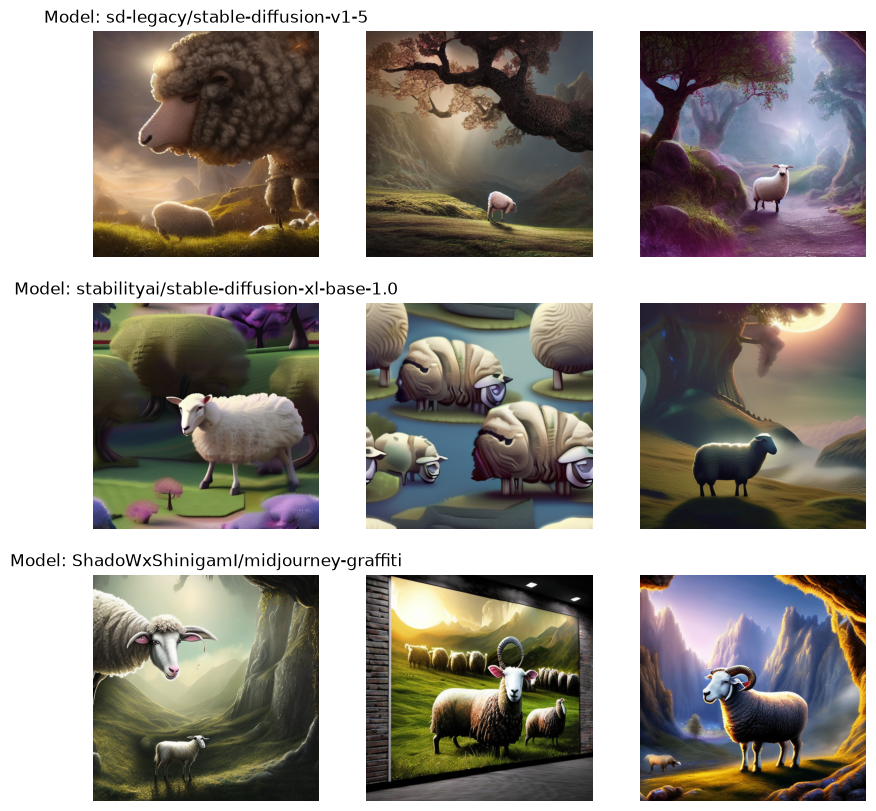

In [29]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(3, 3, figsize=(10, 10))

for i, ax in enumerate(axs.flatten()):
    ax.imshow(images[i])
    ax.axis('off')
    if (i % 3 == 0):
        ax.title.set_text(f"Model: {model_names[int(i / 3)]}")